# 03 - Análisis Exploratorio de Anotaciones

Este notebook cubre la parte de EDA sobre `events.csv` y `plays.csv` (las anotaciones normalizadas que produce `01_data_extraction.ipynb`). El foco es la estructura temporal y categórica de los eventos anotados, no los frames de video.

Preguntas que se buscan responder:
- ¿Qué tan desbalanceadas están las clases de evento (`play`, `throwin`, `challenge`)?
- ¿Cómo se distribuyen los eventos y sus atributos?
- ¿Con qué frecuencia ocurren los eventos en el tiempo (por video, por minuto, entre eventos)?
- ¿Cuánto duran las jugadas (`plays.csv`) y qué tan atípicas son las más largas?
- ¿Los conteos de eventos por video están correlacionados entre sí?


## 1. Configuración

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.options.display.float_format = lambda x: f"{x:,.2f}"

PROCESSED_DIR = "../data/processed"

events = pd.read_csv(f"{PROCESSED_DIR}/events.csv")
plays = pd.read_csv(f"{PROCESSED_DIR}/plays.csv")
video_meta = pd.read_csv(f"{PROCESSED_DIR}/video_meta.csv")

events.head()

,video_id,time_s,event,event_attributes,attr_1,attr_2,is_point_event,clip_num,time_in_clip_s,fps,frame_abs
0,1606b0e6_0,200.27,start,NaN,NaN,NaN,False,7,20.27,NaN,NaN
1,1606b0e6_0,201.15,challenge,['ball_action_forced'],ball_action_forced,NaN,True,7,21.15,NaN,NaN
2,1606b0e6_0,202.77,end,NaN,NaN,NaN,False,7,22.77,NaN,NaN
3,1606b0e6_0,210.12,start,NaN,NaN,NaN,False,8,0.12,NaN,NaN
4,1606b0e6_0,210.87,challenge,['opponent_dispossessed'],opponent_dispossessed,NaN,True,8,0.87,NaN,NaN


## 2. Universo de datos (recordatorio rápido)

La limpieza y descripción completa de variables la cubre la sección de la Persona 2. Aquí
solo se deja constancia del tamaño de las tablas que se usan en este notebook.

In [ ]:
print(f"events.csv : {events.shape[0]:,} filas x {events.shape[1]} columnas | {events['video_id'].nunique()} videos")
print(f"plays.csv  : {plays.shape[0]:,} filas x {plays.shape[1]} columnas | {plays['video_id'].nunique()} videos")

# Los "point events" son las anotaciones reales de la jugada (play/throwin/challenge).
# start/end son marcadores estructurales que delimitan cada jugada en plays.csv.
point_events = events[events["is_point_event"]].copy()
print(f"\nPoint events (play/throwin/challenge): {len(point_events):,}")
print(f"Marcadores start/end: {len(events) - len(point_events):,}")

events.csv : 11,218 filas x 11 columnas | 12 videos
plays.csv  : 3,418 filas x 5 columnas | 12 videos

Point events (play/throwin/challenge): 4,382
Marcadores start/end: 6,836


## 3. Frecuencias y proporciones de `event`

`event` mezcla dos cosas distintas: marcadores estructurales (`start`, `end`, que siempre
vienen en pares y delimitan una jugada) y los eventos de interés (`play`, `challenge`,
`throwin`). Separamos ambos antes de sacar conclusiones.

In [ ]:
event_counts = events["event"].value_counts()
event_pct = (event_counts / len(events) * 100).round(2)
freq_table = pd.DataFrame({"n": event_counts, "%": event_pct})
freq_table

,n,%
event,,
play,3586,31.97
start,3418,30.47
end,3418,30.47
challenge,624,5.56
throwin,172,1.53


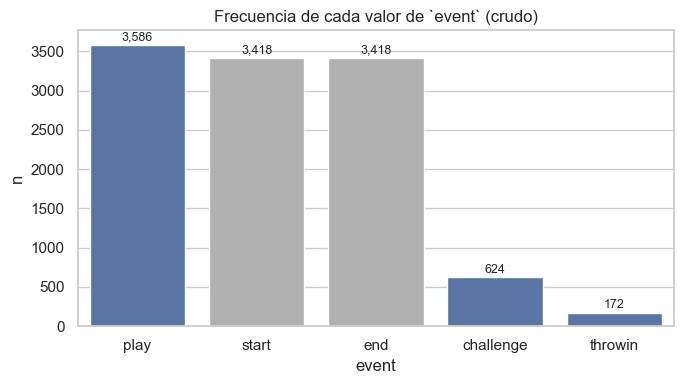

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
order = event_counts.index
colors = ["#4C72B0" if e in ("play", "throwin", "challenge") else "#B0B0B0" for e in order]
sns.barplot(x=order, y=event_counts.values, hue=order, palette=colors, legend=False, ax=ax)
ax.set_title("Frecuencia de cada valor de `event` (crudo)")
ax.set_xlabel("event")
ax.set_ylabel("n")
for i, v in enumerate(event_counts.values):
    ax.text(i, v + 60, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura:** `start` y `end` aparecen en cantidades idénticas (3,418 cada uno), como se
espera de marcadores pareados que delimitan cada jugada. Los "point events" reales
(`play` + `challenge` + `throwin` = 4,382) son el 39% de las filas de `events.csv`. El resto
es estructura, no señal.

## 4. Desbalance de clases entre `play`, `challenge` y `throwin`

In [ ]:
point_counts = point_events["event"].value_counts()
point_pct = (point_counts / len(point_events) * 100).round(2)
point_freq_table = pd.DataFrame({"n": point_counts, "%": point_pct})
point_freq_table

,n,%
event,,
play,3586,81.83
challenge,624,14.24
throwin,172,3.93


In [ ]:
ratio_play_throwin = point_counts["play"] / point_counts["throwin"]
ratio_play_challenge = point_counts["play"] / point_counts["challenge"]
print(f"play / throwin   = {ratio_play_throwin:.1f}x")
print(f"play / challenge = {ratio_play_challenge:.1f}x")

play / throwin   = 20.8x
play / challenge = 5.7x


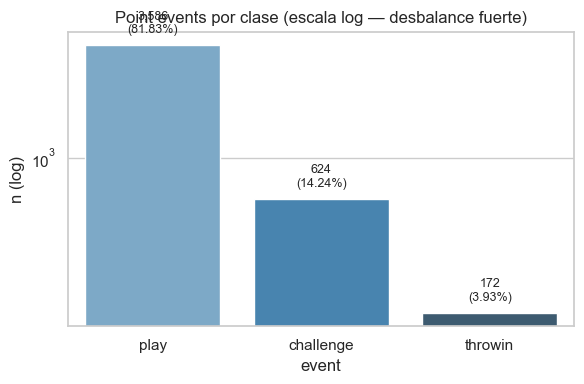

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=point_counts.index, y=point_counts.values, hue=point_counts.index,
            palette="Blues_d", legend=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Point events por clase (escala log — desbalance fuerte)")
ax.set_ylabel("n (log)")
for i, (v, p) in enumerate(zip(point_counts.values, point_pct.values)):
    ax.text(i, v * 1.15, f"{v:,}\n({p}%)", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura:** `play` domina con ~82% de los point events, frente a ~14% de `challenge` y
apenas ~4% de `throwin`. La razón `play`/`throwin` es de aproximadamente 21x, tal como se
había anticipado en el reparto del proyecto. Esto es relevante para cualquier modelo de
clasificación posterior, sin balanceo de clases o métricas adecuadas (F1 por clase, no solo accuracy), un clasificador trivial que siempre prediga `play` ya acertaría ~82% de las veces sin aprender nada útil.

## 5. Atributos de los point events (`attr_1`, `attr_2`)

In [ ]:
attr1_counts = point_events["attr_1"].value_counts(dropna=False)
attr1_pct = (attr1_counts / len(point_events) * 100).round(2)
pd.DataFrame({"n": attr1_counts, "%": attr1_pct})

,n,%
attr_1,,
pass,3622,82.66
ball_action_forced,239,5.45
opponent_dispossessed,138,3.15
cross,136,3.10
fouled,111,2.53
challenge_during_ball_transfer,53,1.21
possession_retained,44,1.00
opponent_rounded,39,0.89


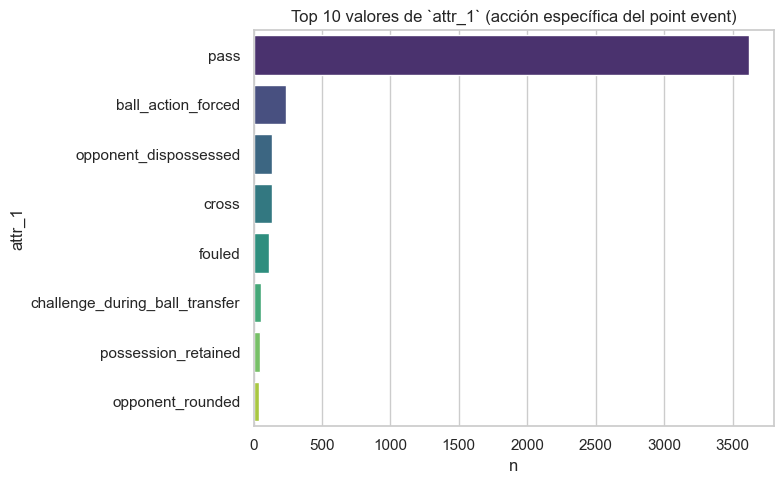

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
top_attr1 = attr1_counts.head(10)
sns.barplot(y=top_attr1.index.astype(str), x=top_attr1.values, hue=top_attr1.index.astype(str),
            palette="viridis", legend=False, ax=ax)
ax.set_title("Top 10 valores de `attr_1` (acción específica del point event)")
ax.set_xlabel("n")
plt.tight_layout()
plt.show()

In [ ]:
attr2_counts = point_events["attr_2"].value_counts(dropna=False)
attr2_pct = (attr2_counts / len(point_events) * 100).round(2)
pd.DataFrame({"n": attr2_counts, "%": attr2_pct})

,n,%
attr_2,,
openplay,3417,77.98
NaN,796,18.17
freekick,132,3.01
corner,37,0.84


In [ ]:
crosstab_event_attr2 = pd.crosstab(point_events["event"], point_events["attr_2"].fillna("(sin dato)"))
crosstab_event_attr2

attr_2,(sin dato),corner,freekick,openplay
event,,,,
challenge,624,0,0,0
play,0,37,132,3417
throwin,172,0,0,0


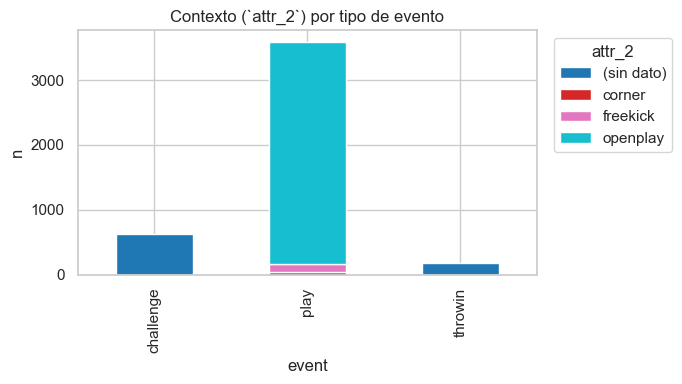

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
crosstab_event_attr2.plot(kind="bar", stacked=True, ax=ax, colormap="tab10")
ax.set_title("Contexto (`attr_2`) por tipo de evento")
ax.set_xlabel("event")
ax.set_ylabel("n")
ax.legend(title="attr_2", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Lectura:** `attr_1` confirma que la inmensa mayoría de los `play` son `pass` (el evento que da nombre al reto). `attr_2` solo aplica a `play` (contexto de balón: `openplay`, `freekick`, `corner`). `challenge` y `throwin` no traen esta subdivisión, lo cual es consistente con la semántica de la anotación original y no un dato faltante por error.

## 6. Eventos por video y por minuto

In [13]:
events_per_video = point_events.groupby("video_id").size().rename("n_events").reset_index()
events_per_video = events_per_video.merge(
    video_meta[["video_id", "has_video", "annot_time_max_s"]], on="video_id", how="left"
)
events_per_video["events_per_min"] = (
    events_per_video["n_events"] / (events_per_video["annot_time_max_s"] / 60)
).round(2)
events_per_video.sort_values("n_events", ascending=False)


,video_id,n_events,has_video,annot_time_max_s,events_per_min
1,1606b0e6_1,507,True,"3,387.70",8.98
4,3c993bd2_0,414,True,"2,999.00",8.28
2,35bd9041_0,411,True,"3,061.90",8.05
0,1606b0e6_0,396,True,"3,014.70",7.88
11,ecf251d4_0,386,False,"3,070.80",7.54
5,3c993bd2_1,376,False,"3,472.40",6.50
3,35bd9041_1,359,True,"3,477.70",6.19
6,407c5a9e_1,350,False,"3,445.20",6.10
9,cfbe2e94_0,305,False,"3,216.90",5.69
7,4ffd5986_0,302,False,"3,099.60",5.85


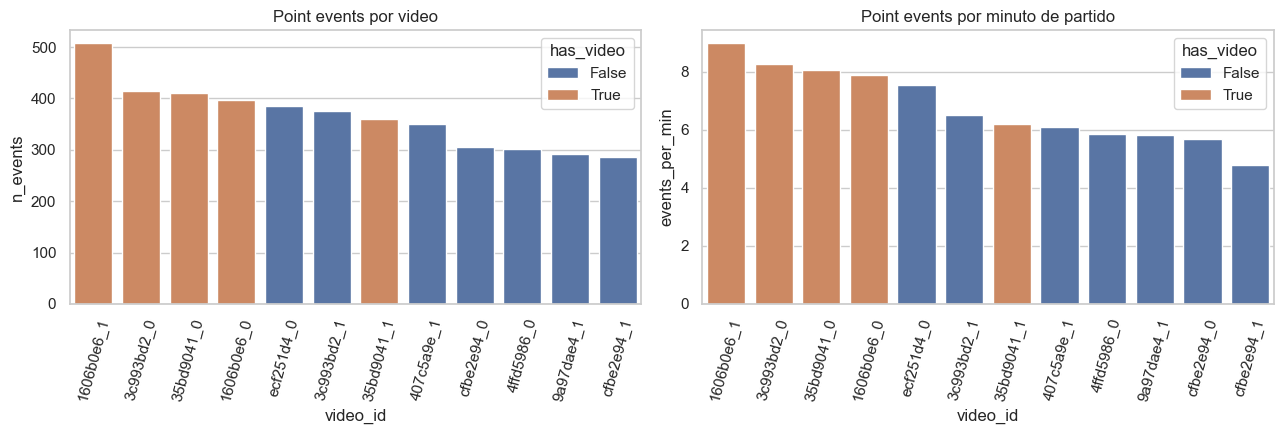

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ev_sorted = events_per_video.sort_values("n_events", ascending=False)
sns.barplot(data=ev_sorted, x="video_id", y="n_events", hue="has_video",
            dodge=False, ax=axes[0])
axes[0].set_title("Point events por video")
axes[0].tick_params(axis="x", rotation=75)

epm_sorted = events_per_video.sort_values("events_per_min", ascending=False)
sns.barplot(data=epm_sorted, x="video_id", y="events_per_min", hue="has_video",
            dodge=False, ax=axes[1])
axes[1].set_title("Point events por minuto de partido")
axes[1].tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()

**Lectura:** el número de point events por video oscila entre 285 y 507 (cada archivo es una mitad de partido), con una tasa de 4.8 a 9.0 point events por minuto de partido. No hay una diferencia sistemática entre los videos que sí tienen footage descargado y los que no. Es decir, la disponibilidad de video (columna `has_video`) no introduce un sesgo obvio en la densidad de anotaciones, lo cual da algo de confianza para extrapolar hallazgos del EDA visual de los 5 videos con footage al resto de partidos.

## 7. Tiempo entre eventos (point events) por video

In [ ]:
def inter_event_gaps(group):
    t = group.sort_values("time_s")["time_s"].values
    return np.diff(t)

gaps_by_video = point_events.groupby("video_id").apply(inter_event_gaps, include_groups=False)
all_gaps = np.concatenate(gaps_by_video.values)
gaps_df = pd.DataFrame({"gap_s": all_gaps})
gaps_df["gap_s"].describe()

count   4,370.00
mean        7.86
std        14.21
min         0.72
25%         2.68
50%         3.80
75%         6.40
max       245.48
Name: gap_s, dtype: float64

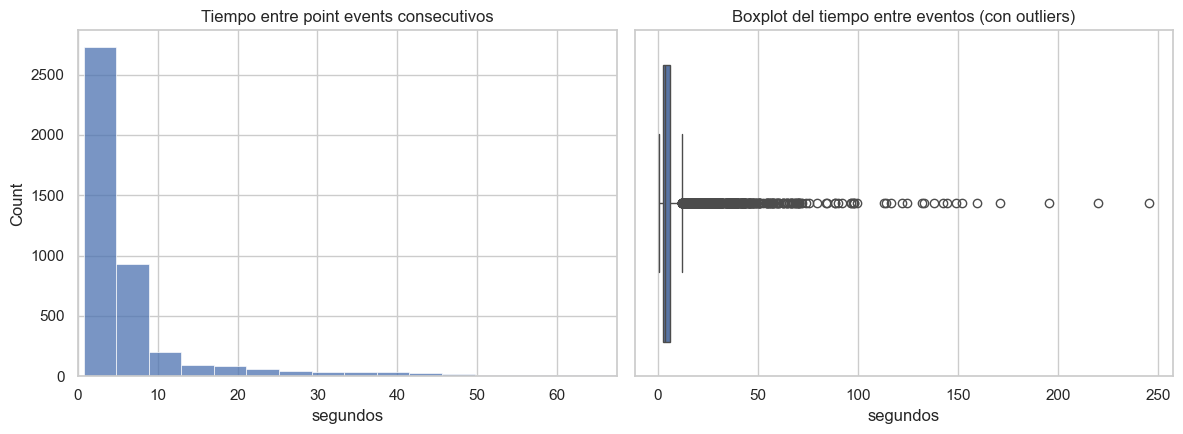

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(gaps_df["gap_s"], bins=60, ax=axes[0])
axes[0].set_title("Tiempo entre point events consecutivos")
axes[0].set_xlabel("segundos")
axes[0].set_xlim(0, gaps_df["gap_s"].quantile(0.99))

sns.boxplot(x=gaps_df["gap_s"], ax=axes[1])
axes[1].set_title("Boxplot del tiempo entre eventos (con outliers)")
axes[1].set_xlabel("segundos")

plt.tight_layout()
plt.show()

In [17]:
q1, q3 = gaps_df["gap_s"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outlier_gaps = gaps_df[gaps_df["gap_s"] > upper_fence]
print(f"Umbral de outlier (Tukey, 1.5*IQR): {upper_fence:.1f} s")
print(f"Gaps atípicamente largos: {len(outlier_gaps)} de {len(gaps_df)} ({len(outlier_gaps)/len(gaps_df)*100:.1f}%)")
print(f"Gap máximo observado: {gaps_df['gap_s'].max():.1f} s")


Umbral de outlier (Tukey, 1.5*IQR): 12.0 s
Gaps atípicamente largos: 541 de 4370 (12.4%)
Gap máximo observado: 245.5 s


**Lectura:** la mayoría de los point events ocurren a pocos segundos uno del otro (mediana baja, distribución con cola larga a la derecha), lo cual es consistente con el juego real: ráfagas de pases seguidas de pausas más largas (faltas, saques de banda que tardan en reanudarse, sustituciones, etc.). Los gaps atípicamente largos (por encima de la cerca de Tukey) probablemente corresponden a paradas de juego no capturadas explícitamente en la anotación (lesiones, revisiones VAR, medio tiempo dentro del mismo archivo, etc.) y son candidatos a inspección manual si se quisiera depurar aún más el dataset.

## 8. Duración de las jugadas (`plays.csv`)

In [18]:
plays["duration_s"].describe()


count   3,418.00
mean        3.05
std         1.16
min         2.50
25%         2.50
50%         2.50
75%         2.50
max        13.99
Name: duration_s, dtype: float64

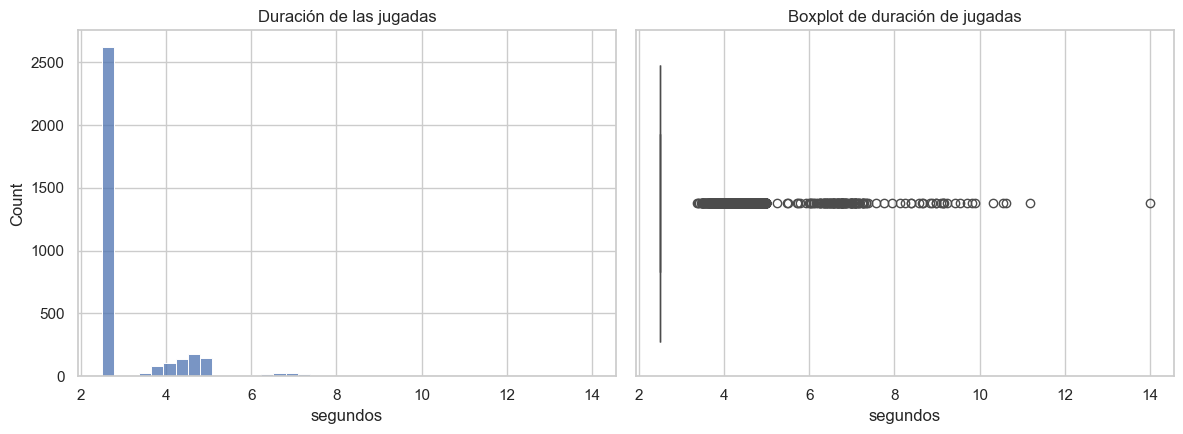

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(plays["duration_s"], bins=40, ax=axes[0])
axes[0].set_title("Duración de las jugadas")
axes[0].set_xlabel("segundos")

sns.boxplot(x=plays["duration_s"], ax=axes[1])
axes[1].set_title("Boxplot de duración de jugadas")
axes[1].set_xlabel("segundos")

plt.tight_layout()
plt.show()


In [20]:
q1, q3 = plays["duration_s"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
long_plays = plays[plays["duration_s"] > upper_fence]
print(f"Duración mínima por diseño: 2.5 s (todas las jugadas parten de esa base)")
print(f"Umbral de outlier (Tukey): {upper_fence:.2f} s")
print(f"Jugadas atípicamente largas: {len(long_plays)} de {len(plays)} ({len(long_plays)/len(plays)*100:.1f}%)")
long_plays.sort_values("duration_s", ascending=False).head(10)


Duración mínima por diseño: 2.5 s (todas las jugadas parten de esa base)
Umbral de outlier (Tukey): 2.50 s
Jugadas atípicamente largas: 796 de 3418 (23.3%)


,video_id,start_s,end_s,duration_s,n_point_events
1435,3c993bd2_0,"1,436.74","1,450.73",13.99,6
1143,35bd9041_1,"1,774.82","1,786.00",11.17,5
817,35bd9041_0,"1,428.11","1,438.74",10.63,5
2019,407c5a9e_1,"1,686.77","1,697.31",10.54,5
611,1606b0e6_1,"2,914.45","2,924.78",10.32,5
1715,3c993bd2_1,"1,741.14","1,751.04",9.90,5
2905,cfbe2e94_1,779.83,789.66,9.83,5
1927,407c5a9e_1,727.05,736.75,9.70,4
3398,ecf251d4_0,"2,938.00","2,947.54",9.54,5
2503,9a97dae4_1,"1,827.29","1,836.71",9.42,4


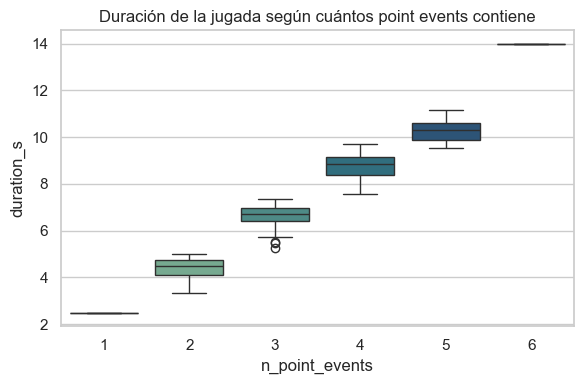

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=plays, x="n_point_events", y="duration_s", hue="n_point_events",
            palette="crest", legend=False, ax=ax)
ax.set_title("Duración de la jugada según cuántos point events contiene")
plt.tight_layout()
plt.show()


**Lectura:** la mayoría de las jugadas duran justo el mínimo de 2.5 s (Q1 = mediana = Q3 = 2.5 s), probablemente una ventana fija que se abre alrededor de cada anotación puntual. Como el rango intercuartil es 0, la cerca de Tukey (Q3 + 1.5·IQR) coincide con el propio mínimo, así que el 23% de jugadas "atípicas" que marca ese criterio en realidad es simplemente el grupo de jugadas que agrupan más de un point event cercano en el tiempo. No son atípicas en el sentido usual, sino un segundo modo de la distribución. Como es de esperar, a más point events agrupados, mayor la duración de la jugada. Esto confirma que `plays.csv` no mide "posesión" en el sentido futbolístico estricto, sino ventanas de anotación consecutivas.

## 9. Correlaciones entre conteos de eventos por video

In [22]:
count_cols = ["n_events", "n_play", "n_throwin", "n_challenge"]
counts_df = video_meta[count_cols]
corr = counts_df.corr()
corr


,n_events,n_play,n_throwin,n_challenge
n_events,1.00,0.98,0.00,0.42
n_play,0.98,1.00,-0.10,0.37
n_throwin,0.00,-0.10,1.00,-0.30
n_challenge,0.42,0.37,-0.30,1.00


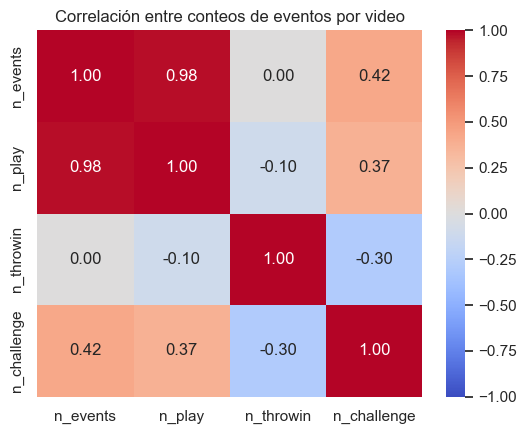

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación entre conteos de eventos por video")
plt.tight_layout()
plt.show()


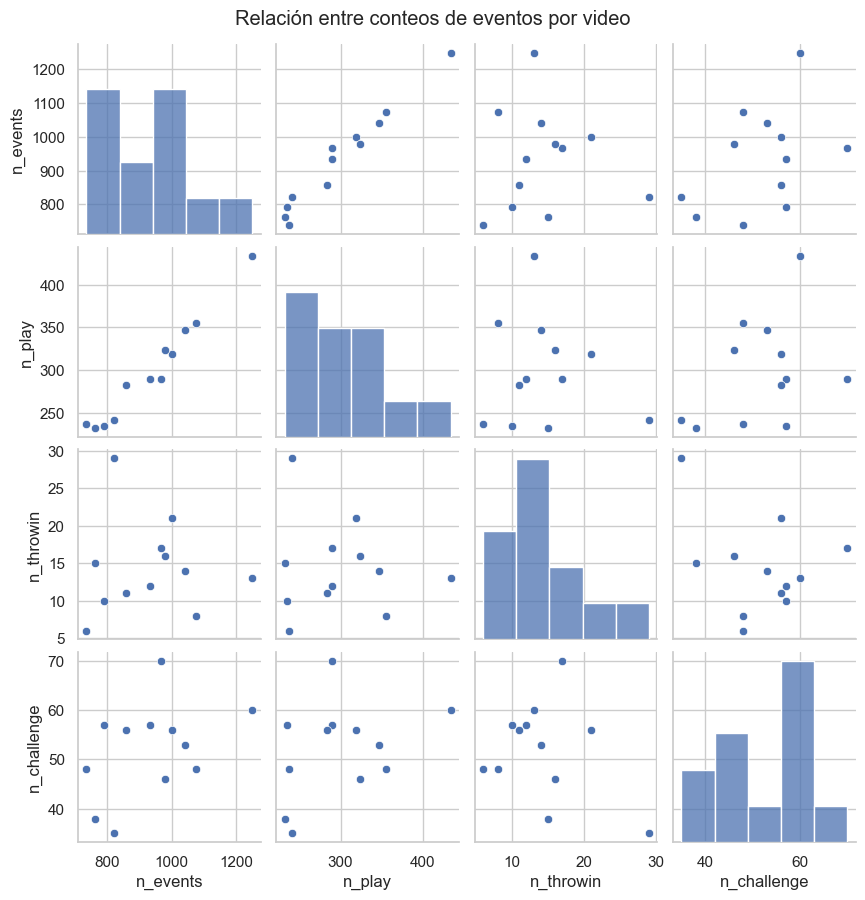

In [24]:
sns.pairplot(counts_df, kind="scatter", diag_kind="hist", height=2.2)
plt.suptitle("Relación entre conteos de eventos por video", y=1.02)
plt.show()


**Lectura:** con solo 12 videos la correlación es exploratoria (no concluyente estadísticamente), pero `n_events` está fuertemente correlacionado con `n_play`, mientras que `n_throwin` y `n_challenge` varían más de forma independiente entre partidos. Probablemente reflejan el estilo de juego de cada partido en particular (más faltas/disputas en unos, más saques de banda en otros) más que una proporción fija.

## 10. Línea de tiempo de eventos

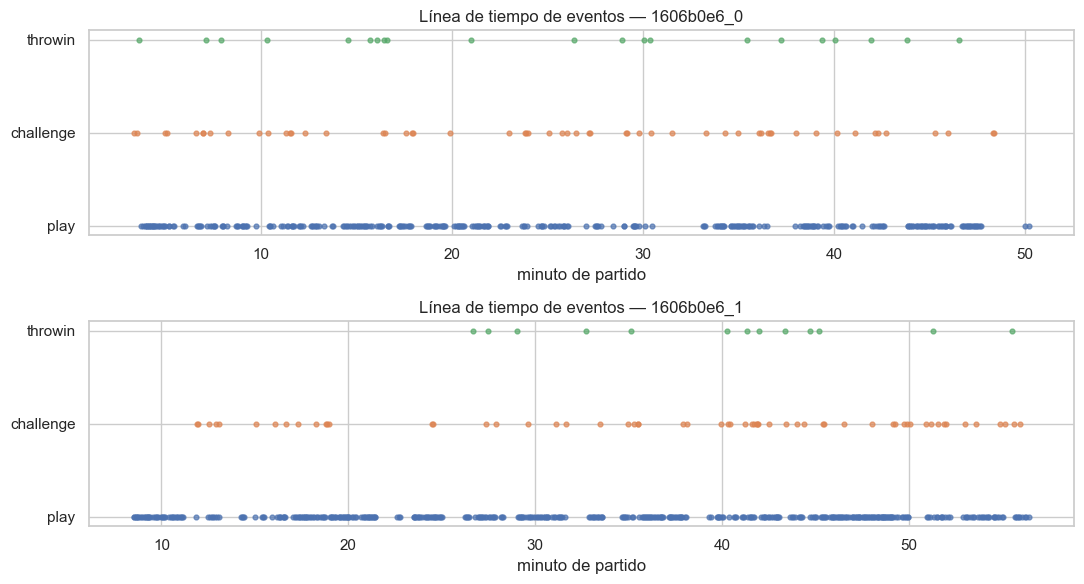

In [25]:
sample_videos = point_events["video_id"].unique()[:2]
fig, axes = plt.subplots(len(sample_videos), 1, figsize=(11, 3 * len(sample_videos)), sharex=False)
palette = {"play": "#4C72B0", "challenge": "#DD8452", "throwin": "#55A868"}

for ax, vid in zip(np.atleast_1d(axes), sample_videos):
    sub = point_events[point_events["video_id"] == vid]
    for ev, color in palette.items():
        pts = sub[sub["event"] == ev]
        ax.scatter(pts["time_s"] / 60, [ev] * len(pts), color=color, s=12, alpha=0.7)
    ax.set_title(f"Línea de tiempo de eventos — {vid}")
    ax.set_xlabel("minuto de partido")

plt.tight_layout()
plt.show()


**Lectura:** los `play` se distribuyen de forma densa y pareja a lo largo de todo el partido, mientras que `throwin` y `challenge` aparecen más dispersos. Visualmente se nota que la clase minoritaria no está concentrada en un tramo específico del partido, así que un futuro split train/val por tiempo (en vez de aleatorio) no debería introducir un sesgo severo de clase.

## 11. Hallazgos

- **Desbalance fuerte de clases**: entre los point events reales, `play` representa ~82%, `challenge` ~14% y `throwin` ~4%. La razón `play`/`throwin` es de aproximadamente 21x, lo que exige usar métricas por clase (F1, recall) y técnicas de balanceo si se entrena un clasificador, en vez de confiar en accuracy global.
- **`attr_1`/`attr_2` confirman la semántica del reto**: casi todos los `play` son `pass`, y el contexto de balón (`openplay`/`freekick`/`corner`) solo aplica a esa clase. No es un dato faltante, es una regla de negocio de la anotación original.
- **Densidad de eventos con variación moderada entre videos**: entre 4.8 y 9.0 point events por minuto en los 12 partidos, sin diferencia sistemática entre los que tienen footage descargado y los que no, lo que da algo de confianza para generalizar el EDA visual al resto de partidos.
- **El tiempo entre eventos tiene cola larga**: mediana de 3.8 s entre point events consecutivos, pero con máximos de hasta 245. Esos gaps atípicamente largos probablemente corresponden a paradas de partido no anotadas explícitamente (lesiones, medio tiempo dentro del mismo archivo, etc.).
- **La duración de las jugadas está anclada a una ventana mínima de 2.5 s**: solo crece cuando se agrupan varios point events cercanos. `plays.csv` mide ventanas de anotación, no posesión real de balón.
- **Las correlaciones entre conteos por video son exploratorias** (n=12): `n_events` está dominado por `n_play` (r≈0.98), mientras que `n_throwin` y `n_challenge` varían de forma más independiente entre partidos (r cercano a 0 o incluso negativo con `n_throwin`), sugiriendo diferencias de estilo de juego entre encuentros.